In [1]:
import os, sys
import warnings
warnings.filterwarnings('ignore')
from IPython.display import display, Markdown, Math
import numpy as np
import pandas as pd
import networkx as nx
from scipy.stats import norm
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)

# Versión local de la librería: se busca src/pmule.py subiendo desde el directorio actual
_aqui = os.path.abspath('.')
while _aqui != os.path.dirname(_aqui) and not os.path.isfile(os.path.join(_aqui, 'src', 'pmule.py')):
    _aqui = os.path.dirname(_aqui)
sys.path.append(os.path.join(_aqui, 'src'))
from pmule import (PredecessorTable, ProjectGraph, EarnedValue,
                   pinta_tikz, plot_cargas, plot_curvas_valor_ganado,
                   tanto_por_uno, ordena_rutas)

GANTT_PARAMS = dict(arrows=True)   # flechas de prelación en los diagramas de Gantt (rojas las críticas)

In [2]:
# Funciones auxiliares para mostrar los cálculos intermedios paso a paso
from itertools import combinations as _combinations


def detalle_tiempos_nodos(proyecto, duraciones):
    """Tiempos tempranos y tardíos de los nodos con los candidatos que se comparan en cada uno."""
    G = proyecto.pert_graph
    d = {data['activity']: (0 if data['activity'].startswith('@') else int(duraciones[data['activity']]))
         for _, _, data in G.edges(data=True)}
    nodos = list(proyecto.nodes)
    early, filas = {}, []
    for j in nodos:
        entrantes = [(i, data['activity']) for i, _, data in G.in_edges(j, data=True)]
        if not entrantes:
            early[j] = 0
            filas.append({'nodo': j, 'candidatos t_i + d_ij': 'nodo inicial', 'tiempo temprano = máx': 0})
            continue
        cand = {f'{a}: {early[i]} + {d[a]} = {early[i] + d[a]}': early[i] + d[a] for i, a in entrantes}
        early[j] = max(cand.values())
        filas.append({'nodo': j, 'candidatos t_i + d_ij': '; '.join(cand), 'tiempo temprano = máx': early[j]})
    tempranos = pd.DataFrame(filas).set_index('nodo')
    late, filas = {}, []
    for i in reversed(nodos):
        salientes = [(j, data['activity']) for _, j, data in G.out_edges(i, data=True)]
        if not salientes:
            late[i] = early[i]
            filas.append({'nodo': i, 'candidatos t*_j − d_ij': 'nodo final (= su tiempo temprano)', 'tiempo tardío = mín': late[i]})
            continue
        cand = {f'{a}: {late[j]} − {d[a]} = {late[j] - d[a]}': late[j] - d[a] for j, a in salientes}
        late[i] = min(cand.values())
        filas.append({'nodo': i, 'candidatos t*_j − d_ij': '; '.join(cand), 'tiempo tardío = mín': late[i]})
    tardios = pd.DataFrame(filas).set_index('nodo')
    return tempranos, tardios


def detalle_holguras(calendario, prelaciones):
    """Cómo se obtiene cada fecha y cada holgura a partir de las vecinas."""
    pred = prelaciones.immediate_predecessor
    suc = {a: sorted(s for s, ps in pred.items() if a in ps) for a in calendario.index}
    fin = int(calendario['fin_mas_temprano'].max())
    filas = []
    for a in calendario.index:
        ES, EF = int(calendario.loc[a, 'inicio_mas_temprano']), int(calendario.loc[a, 'fin_mas_temprano'])
        LS, LF = int(calendario.loc[a, 'inicio_mas_tardio']), int(calendario.loc[a, 'fin_mas_tardio'])
        dur = int(calendario.loc[a, 'duracion'])
        ps, ss = sorted(pred[a]), suc[a]
        ef_pred = {p: int(calendario.loc[p, 'fin_mas_temprano']) for p in ps}
        es_suc = {s: int(calendario.loc[s, 'inicio_mas_temprano']) for s in ss}
        lf_pred = {p: int(calendario.loc[p, 'fin_mas_tardio']) for p in ps}
        ls_suc = {s: int(calendario.loc[s, 'inicio_mas_tardio']) for s in ss}
        min_es_suc = min(es_suc.values()) if es_suc else fin
        max_lf_pred = max(lf_pred.values()) if lf_pred else 0
        filas.append({
            'actividad': a,
            'ES = máx EF pred.': (f"máx({', '.join(f'{p}: {v}' for p, v in ef_pred.items())}) = {ES}" if ps else f'inicial → {ES}'),
            'EF = ES + d': f'{ES} + {dur} = {EF}',
            'LF = mín LS suc.': (f"mín({', '.join(f'{s}: {v}' for s, v in ls_suc.items())}) = {LF}" if ss else f'final → {LF}'),
            'LS = LF − d': f'{LF} − {dur} = {LS}',
            'H_total = LS − ES': f'{LS} − {ES} = {LS - ES}',
            'H_libre = mín ES suc. − EF': f"{min_es_suc}{'' if ss else ' (fin)'} − {EF} = {min_es_suc - EF}",
            'H_indep. = máx(0, mín ES suc. − máx LF pred. − d)': f'máx(0, {min_es_suc} − {max_lf_pred} − {dur}) = {max(0, min_es_suc - max_lf_pred - dur)}',
        })
    return pd.DataFrame(filas).set_index('actividad')


def detalle_rutas(R, valores, nombre='duración', decimales=0):
    """Suma término a término de un valor (duraciones, varianzas…) a lo largo de cada ruta."""
    filas = {}
    for r in R.index:
        acts = list(R.columns[R.loc[r] == 1])
        total = float(sum(valores[a] for a in acts))
        filas[r] = {'actividades': ' - '.join(acts),
                    f'{nombre} = suma': ' + '.join(f'{a}({valores[a]:.{decimales}f})' for a in acts) + f' = {total:.{decimales}f}',
                    nombre: total}
    return pd.DataFrame(filas).T


def detalle_estimaciones(datos, a='a', m='m', b='b'):
    """Media y varianza PERT de cada actividad con los números sustituidos."""
    filas = {}
    for act, fila in datos.iterrows():
        A, M, B = float(fila[a]), float(fila[m]), float(fila[b])
        filas[act] = {'D = (a + 4m + b)/6': f'({A:g} + 4·{M:g} + {B:g})/6 = {(A + 4 * M + B) / 6:.2f}',
                      'σ² = ((b − a)/6)²': f'(({B:g} − {A:g})/6)² = {((B - A) / 6) ** 2:.3f}'}
    return pd.DataFrame(filas).T


def detalle_ackoff(proyecto, duraciones, topes, cur, pasos):
    """En cada paso de Ackoff-Sasieni: rutas críticas, opciones consideradas (actividades comunes y parejas)
    con su coste, y la elegida."""
    R = proyecto.path_matrix(dummies=False)
    d = duraciones.astype(float).copy()
    filas = []
    for paso, elegidas in sorted(pasos.items()):
        L = R @ d[R.columns]
        T = float(L.max())
        criticas = [r for r in L.index if np.isclose(L[r], T)]
        conjuntos = [set(R.columns[R.loc[r] == 1]) for r in criticas]
        con_margen = {x for x in R.columns if d[x] > topes[x] and np.isfinite(cur[x])}
        opciones = {x: float(cur[x]) for x in set.intersection(*conjuntos) & con_margen}
        if len(conjuntos) > 1:
            cand = sorted(set().union(*conjuntos) & con_margen)
            for p, q in _combinations(cand, 2):
                if all(p in s or q in s for s in conjuntos) and p not in opciones and q not in opciones:
                    opciones[f'{p}+{q}'] = float(cur[p] + cur[q])
        orden = sorted(opciones.items(), key=lambda kv: kv[1])
        filas.append({'paso': paso + 1, 'duración': int(T), 'rutas críticas': ', '.join(criticas),
                      'opciones (coste)': '; '.join(f'{k} ({v:.0f})' for k, v in orden[:6]) + (' …' if len(orden) > 6 else ''),
                      'elegida': ', '.join(elegidas), 'coste del paso': float(sum(cur[x] for x in elegidas))})
        for x in elegidas:
            d[x] -= 1
    return pd.DataFrame(filas).set_index('paso')


def detalle_valor_ganado(datos_vg, calendario, semana):
    """PV, EV y AC actividad a actividad en el punto de control."""
    filas = {}
    for a, fila in datos_vg.iterrows():
        es, dur = int(calendario.loc[a, 'inicio_mas_temprano']), int(calendario.loc[a, 'duracion'])
        frac = min(max(semana - es, 0), dur) / dur
        filas[a] = {'BAC': float(fila['BAC']), 'planificado hasta la semana': f'{min(max(semana - es, 0), dur)} de {dur}',
                    'PV = BAC·fracción': f'{fila["BAC"]:.0f}·{frac:.2f} = {fila["BAC"] * frac:.1f}',
                    'realizado (%)': int(fila['performed']),
                    'EV = BAC·%': f'{fila["BAC"]:.0f}·{fila["performed"] / 100:.2f} = {fila["BAC"] * fila["performed"] / 100:.1f}',
                    'AC': float(fila['AC']), 'PV_i': fila['BAC'] * frac, 'EV_i': fila['BAC'] * fila['performed'] / 100}
    t = pd.DataFrame(filas).T
    return t


def muestra_formula(nombre, expresion, valor, unidades=''):
    """Una línea «nombre = expresión = valor» en Markdown."""
    return Markdown(f'**{nombre}** = {expresion} = **{valor}**{(" " + unidades) if unidades else ""}')

In [3]:
%%capture
%mkdir -p ~/temp
%cd ~/temp

# Enunciado

Considere el proyecto cuyo cuadro de prelaciones y duraciones medias (semanas) se adjunta. Cada actividad sigue una distribución distinta, según la información disponible sobre ella: normal (media y desviación típica), triangular (mínimo, moda, máximo), uniforme (mínimo, máximo) o fija (duración cierta).

In [4]:
#| tbl-cap: "Cuadro de prelaciones y duraciones medias"
#| label: tbl-datosEnunciado
datos_enunciado = pd.DataFrame([
#  activity, predecessor, duration
    ('A'     , '---'      , 8       ),
    ('B'     , '---'      , 3       ),
    ('C'     , '---'      , 4       ),
    ('D'     , 'A,B,C'    , 6       ),
    ('E'     , 'D'        , 4       ),
    ('F'     , 'E'        , 4       ),
    ('G'     , 'F'        , 6       ),
    ('H'     , 'F'        , 3       ),
    ('I'     , 'G,H'      , 3       ),
], columns=['activity', 'predecessor', 'duration']).set_index('activity')
datos_enunciado

,predecessor,duration
activity,,
A,---,8
B,---,3
C,---,4
D,"A,B,C",6
E,D,4
F,E,4
G,F,6
H,F,3
I,"G,H",3


El proyecto corresponde a la apertura de una clínica veterinaria; las actividades son las siguientes (las duraciones del cuadro están en semanas).

In [5]:
#| tbl-cap: "Descripción de las actividades"
#| label: tbl-descripciones
descripciones = pd.Series({
    'A': 'Estudio de mercado y local',
    'B': 'Proyecto de reforma y licencia',
    'C': 'Obra de reforma',
    'D': 'Instalación de quirófano y radiología',
    'E': 'Mobiliario y equipamiento clínico',
    'F': 'Software de gestión',
    'G': 'Selección de personal',
    'H': 'Acuerdos con proveedores',
    'I': 'Registro sanitario',
}, name='Descripción')
descripciones.to_frame()

,Descripción
A,Estudio de mercado y local
B,Proyecto de reforma y licencia
C,Obra de reforma
D,Instalación de quirófano y radiología
E,Mobiliario y equipamiento clínico
F,Software de gestión
G,Selección de personal
H,Acuerdos con proveedores
I,Registro sanitario


In [6]:
#| tbl-cap: "Distribución de la duración de cada actividad"
#| label: tbl-distribuciones
distribuciones = pd.DataFrame([
#  activity, distribucion, parametros           
    ('A'     , 'uniforme'  , 'a = 7, b = 9'       ),
    ('B'     , 'fija'      , '3'                  ),
    ('C'     , 'normal'    , 'μ = 4, σ = 1.0'     ),
    ('D'     , 'uniforme'  , 'a = 5, b = 7'       ),
    ('E'     , 'uniforme'  , 'a = 2, b = 6'       ),
    ('F'     , 'fija'      , '4'                  ),
    ('G'     , 'normal'    , 'μ = 6, σ = 0.5'     ),
    ('H'     , 'triangular', 'a = 2, m = 3, b = 4'),
    ('I'     , 'normal'    , 'μ = 3, σ = 1.0'     ),
], columns=['activity', 'distribucion', 'parametros']).set_index('activity')
distribuciones

,distribucion,parametros
activity,,
A,uniforme,"a = 7, b = 9"
B,fija,3
C,normal,"μ = 4, σ = 1.0"
D,uniforme,"a = 5, b = 7"
E,uniforme,"a = 2, b = 6"
F,fija,4
G,normal,"μ = 6, σ = 0.5"
H,triangular,"a = 2, m = 3, b = 4"
I,normal,"μ = 3, σ = 1.0"


In [7]:
pregunta_1 = "1. Calcule la media y la varianza de cada actividad según su distribución y compruebe que las medias coinciden con las duraciones medias del cuadro.  "
pregunta_2 = "2. Determine la ruta crítica con las medias y la probabilidad de terminar en la duración media más dos semanas según la aproximación normal.  "
pregunta_3 = "3. Simule el proyecto con 20 000 réplicas usando la distribución de cada actividad (las fijas no varían). Compare media, desviación típica y la probabilidad anterior.  "
pregunta_4 = "4. ¿Qué actividad tiene mayor índice de criticidad sin ser crítica en media? ¿Influye en ello que alguna actividad sea de duración fija?  "

for item in sorted(dir()):
    if item.startswith('pregunta_'):
        display(Markdown(eval(item)))

1. Calcule la media y la varianza de cada actividad según su distribución y compruebe que las medias coinciden con las duraciones medias del cuadro.  

2. Determine la ruta crítica con las medias y la probabilidad de terminar en la duración media más dos semanas según la aproximación normal.  

3. Simule el proyecto con 20 000 réplicas usando la distribución de cada actividad (las fijas no varían). Compare media, desviación típica y la probabilidad anterior.  

4. ¿Qué actividad tiene mayor índice de criticidad sin ser crítica en media? ¿Influye en ello que alguna actividad sea de duración fija?  

# Resolución

In [8]:
datos_proyecto = datos_enunciado.copy()
prelaciones = PredecessorTable.from_dataframe_of_strings(datos_proyecto, activity='activity', predecessor='predecessor')
proyecto = prelaciones.create_project()
import re
def parametros(texto):
    return [float(x) for x in re.findall(r'[-+]?\d*\.?\d+', texto)]

## Apartado 1

In [9]:
display(Markdown(pregunta_1))

1. Calcule la media y la varianza de cada actividad según su distribución y compruebe que las medias coinciden con las duraciones medias del cuadro.  

In [10]:
filas = {}
for act, fila in distribuciones.iterrows():
    p = parametros(fila['parametros'])
    if fila['distribucion'] == 'normal':
        media, var = p[0], p[1] ** 2
    elif fila['distribucion'] == 'triangular':
        a, m, b = p; media, var = (a + m + b) / 3, (a*a + m*m + b*b - a*b - a*m - b*m) / 18
    elif fila['distribucion'] == 'uniforme':
        a, b = p; media, var = (a + b) / 2, (b - a) ** 2 / 12
    else:
        media, var = p[0], 0.0
    filas[act] = {'distribución': fila['distribucion'], 'media': media, 'varianza': var}
resumen = pd.DataFrame(filas).T
resumen['media del cuadro'] = datos_proyecto['duration']
datos_proyecto['variance'] = resumen['varianza'].astype(float)
resumen

,distribución,media,varianza,media del cuadro
A,uniforme,8.0,0.333333,8
B,fija,3.0,0.0,3
C,normal,4.0,1.0,4
D,uniforme,6.0,0.333333,6
E,uniforme,4.0,1.333333,4
F,fija,4.0,0.0,4
G,normal,6.0,0.25,6
H,triangular,3.0,0.166667,3
I,normal,3.0,1.0,3


## Apartado 2

In [11]:
display(Markdown(pregunta_2))

2. Determine la ruta crítica con las medias y la probabilidad de terminar en la duración media más dos semanas según la aproximación normal.  

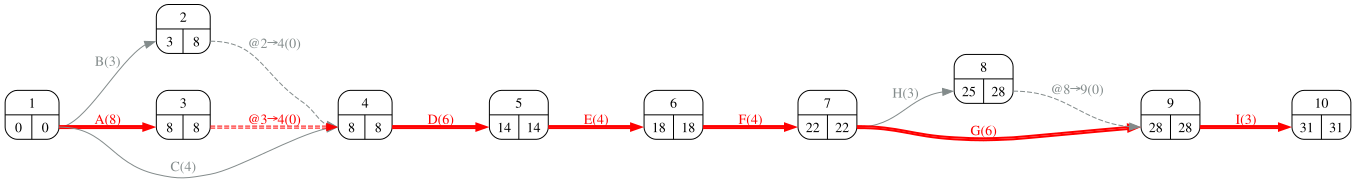

In [12]:
#| fig-cap: "Grafo PERT con duraciones medias y camino crítico"
#| label: fig-pert
proyecto.pert(durations=datos_proyecto['duration'], ranksep=1)

In [13]:
duracion_media = proyecto.duration(datos_proyecto['duration'])
desviacion_proyecto, varianza_rutas = proyecto.standard_deviation(datos_proyecto['duration'], datos_proyecto['variance'])
plazo = duracion_media + 2
p_normal = float(norm.cdf((plazo - duracion_media) / desviacion_proyecto)) if desviacion_proyecto > 0 else 1.0
Markdown(f'Duración media {duracion_media}, σ = {desviacion_proyecto:.3f}; P(T ≤ {plazo}) = {p_normal:.3f} por la aproximación normal.')

Duración media 31, σ = 1.803; P(T ≤ 33) = 0.866 por la aproximación normal.

## Apartado 3

In [14]:
display(Markdown(pregunta_3))

3. Simule el proyecto con 20 000 réplicas usando la distribución de cada actividad (las fijas no varían). Compare media, desviación típica y la probabilidad anterior.  

`monte_carlo` acepta una distribución por actividad: `('normal', μ, σ)`, `('triangular', a, m, b)`, `('uniform', a, b)` o una función; una duración fija es una función que siempre devuelve el mismo valor.

In [15]:
dists = {}
for act, fila in distribuciones.iterrows():
    p = parametros(fila['parametros'])
    if fila['distribucion'] == 'normal':
        dists[act] = ('normal', p[0], p[1])
    elif fila['distribucion'] == 'triangular':
        dists[act] = ('triangular', p[0], p[1], p[2])
    elif fila['distribucion'] == 'uniforme':
        dists[act] = ('uniform', p[0], p[1])
    else:
        dists[act] = (lambda valor: (lambda size=None: np.full(size, valor) if size else valor))(p[0])
resultado = proyecto.monte_carlo(dists, n_samples=20000, seed=11)
p_mc = float((resultado.tau_samples <= plazo).mean())
display(resultado.summary().round(2))
pd.DataFrame({'aproximación normal': [duracion_media, desviacion_proyecto, p_normal], 'Monte Carlo': [resultado.tau_mean, resultado.tau_std, p_mc]},
             index=['media', 'desviación típica', f'P(T ≤ {plazo})']).round(3)

,mean,std,q05,q50,q95,min,max
τ,31.0,1.81,28.04,31.0,33.99,24.2,37.76


,aproximación normal,Monte Carlo
media,31.000,30.998
desviación típica,1.803,1.807
P(T ≤ 33),0.866,0.861


## Apartado 4

In [16]:
display(Markdown(pregunta_4))

4. ¿Qué actividad tiene mayor índice de criticidad sin ser crítica en media? ¿Influye en ello que alguna actividad sea de duración fija?  

In [17]:
calendario = proyecto.calendar(datos_proyecto['duration'])
crit = (resultado.sensitivity_mean * 100).round(1).rename('índice de criticidad (%)')
tabla = pd.concat([crit, calendario['H_total'].rename('holgura'), resumen['distribución'], resumen['varianza'].astype(float).round(2)], axis=1).sort_values('índice de criticidad (%)', ascending=False)
tabla

,índice de criticidad (%),holgura,distribución,varianza
E,100.0,0,uniforme,1.33
I,100.0,0,normal,1.00
D,100.0,0,uniforme,0.33
G,100.0,0,normal,0.25
F,100.0,0,fija,0.00
A,100.0,0,uniforme,0.33
C,0.0,4,normal,1.00
B,0.0,5,fija,0.00
H,0.0,3,triangular,0.17


In [18]:
vigilar = tabla[tabla['holgura'] > 0]['índice de criticidad (%)'].idxmax()
Markdown(f'''La actividad no crítica con mayor índice de criticidad es {vigilar} ({tabla.loc[vigilar, "índice de criticidad (%)"]} %). Las actividades de duración fija nunca cambian de ruta por sí mismas: su índice depende sólo de lo que hagan las demás; una ruta con muchas actividades fijas tiene poca varianza y rara vez «adelanta» a la crítica.''')

La actividad no crítica con mayor índice de criticidad es C (0.0 %). Las actividades de duración fija nunca cambian de ruta por sí mismas: su índice depende sólo de lo que hagan las demás; una ruta con muchas actividades fijas tiene poca varianza y rara vez «adelanta» a la crítica.